# 1D Spectral analysis

In this tutorial, we present the basics steps for a 1D spectral analysis. The main aim is to perform a spectral analysis of a point-like source. A spectral analysis consist in stacking all events in the region of interest. Doing this we forget about the spatial information of the source. This is why the 1D analysis is best suited for point-like sources. 

To estimate the background, we will use off regions taken on the data using reflected regions. 

## 1. Crab Nebula

### 1.1 Full containment IRFs: H.E.S.S. data

We are going to analyse the data from the High Energy Stereoscopic System (H.E.S.S.) towards the Crab nebula.  

Let's start with some basic imports:

In [1]:
from gammapy.data import DataStore
from gammapy.maps import MapAxis, RegionGeom, WcsGeom
from gammapy.makers import SpectrumDatasetMaker, ReflectedRegionsBackgroundMaker, SafeMaskMaker, WobbleRegionsFinder
from gammapy.datasets import SpectrumDataset, Datasets
from gammapy.modeling.models import PowerLawSpectralModel, SkyModel, ExpCutoffPowerLawSpectralModel, LogParabolaSpectralModel
from gammapy.modeling import Fit
from gammapy.estimators import FluxPointsEstimator
from gammapy.visualization import plot_spectrum_datasets_off_regions

from astropy.coordinates import SkyCoord
import astropy.units as u
from regions import CircleSkyRegion, PointSkyRegion

import matplotlib.pyplot as plt
import numpy as np

Create a DataStore instance using the following path to H.E.S.S. data: `$GAMMAPY_DATA/hess-dl3-dr1`.

In [2]:
data_store = DataStore.from_dir("$GAMMAPY_DATA/hess-dl3-dr1")

Get the Crab coordinates using astropy `SkyCoord`.

In [3]:
target_position = SkyCoord.from_name("Crab")

To select the relevant runs, we can use the `obs_table` associated to the `DataStore`.

In [5]:
obs_table = data_store.obs_table
obs_table

OBS_ID,RA_PNT,DEC_PNT,GLON_PNT,GLAT_PNT,ZEN_PNT,ALT_PNT,AZ_PNT,OBJECT,RA_OBJ,DEC_OBJ,OFFSET_OBJ,ONTIME,LIVETIME,DEADC,TSTART,TSTOP,DATE-OBS,TIME-OBS,DATE-END,TIME-END,N_TELS,TELLIST,QUALITY,MUONEFF,EVENT_COUNT,TARGET_NAME,TARGET_TAG,TARGET_OFFSET,SAFE_ENERGY_LO,SAFE_ENERGY_HI
,deg,deg,deg,deg,deg,deg,deg,,deg,deg,deg,s,s,,s,s,,,,,,,,,,,,deg,TeV,TeV
int64,float32,float32,float32,float32,float32,float32,float32,bytes18,float32,float32,float32,float32,float32,float32,float64,float64,bytes10,bytes12,bytes10,bytes12,int64,bytes7,int64,float32,int64,bytes21,bytes14,float32,float32,float32
20136,228.6125,-58.771667,320.56754,-0.8857012,38.512962,51.487038,195.73102,MSH15-52,228.6125,-59.271667,0.5,1682.0,1521.0269,0.9042966,101962602.0,101964284.0,2004-03-26,02:57:46.184,2004-03-26,03:25:48.184,4,"1,2,3,4",0,1.2132596,11243,MSH 15-52,msh1552,0.38821736,0.40738028,100.0
20137,228.6125,-59.771667,320.04724,-1.7397733,40.21616,49.78384,199.6482,MSH15-52,228.6125,-59.271667,0.5,902.0,819.2054,0.90821,101964441.0,101965343.0,2004-03-26,03:28:25.184,2004-03-26,03:43:27.184,4,"1,2,3,4",0,1.2139559,5693,MSH 15-52,msh1552,0.6156251,0.40738028,100.0
20151,228.6125,-58.771667,320.56754,-0.8857012,37.164658,52.835342,190.97171,custom,228.6125,-59.271667,0.5,1683.0,1530.479,0.9093755,102047232.0,102048915.0,2004-03-27,02:28:16.184,2004-03-27,02:56:19.184,4,"1,2,3,4",0,1.2214733,10722,MSH 15-52,msh1552,0.38821736,0.40738028,100.0
20275,187.27792,2.552389,289.7155,64.849686,36.18243,53.81757,49.144917,3C 273,187.27792,2.052389,0.5,1683.0,1525.8447,0.90662193,103665036.0,103666719.0,2004-04-14,19:51:40.184,2004-04-14,20:19:43.184,4,"1,2,3,4",0,1.121256,10646,Off data,offdata,--,0.33113113,100.0
20282,228.6125,-58.771667,320.56754,-0.8857012,37.13134,52.86866,169.21602,MSH 15-5-02,228.6125,-59.271667,0.5,1687.0,1543.3231,0.9148329,103678269.0,103679956.0,2004-04-14,23:32:13.184,2004-04-15,00:00:20.184,4,"1,2,3,4",0,1.1495326,11063,MSH 15-52,msh1552,0.38821736,0.40738028,100.0
20283,228.6125,-59.771667,320.04724,-1.7397733,36.221436,53.778564,175.77263,MSH 15-5-02,228.6125,-59.271667,0.5,1683.0,1547.8253,0.9196823,103680087.0,103681770.0,2004-04-15,00:02:31.184,2004-04-15,00:30:34.184,4,"1,2,3,4",0,1.1512518,7628,MSH 15-52,msh1552,0.6156251,0.3801894,100.0
20301,228.6125,-58.771667,320.56754,-0.8857012,36.839905,53.160095,171.07347,MSH 15-5-02,228.6125,-59.271667,0.5,1683.0,1534.0626,0.9115048,103764878.0,103766561.0,2004-04-15,23:35:42.184,2004-04-16,00:03:45.184,4,"1,2,3,4",0,1.1503073,11624,MSH 15-52,msh1552,0.38821736,0.40738028,100.0
20302,228.6125,-59.771667,320.04724,-1.7397733,36.11632,53.88368,177.10521,MSH 15-5-02,228.6125,-59.271667,0.5,1682.0,1535.3478,0.9128108,103766698.0,103768380.0,2004-04-16,00:06:02.184,2004-04-16,00:34:04.184,4,"1,2,3,4",0,1.1493496,11794,MSH 15-52,msh1552,0.6156251,0.3801894,100.0


Using `select_sky_circle` method of `obs_table`, select run that are at most at 2.2 deg from the Crab Nebula.

In [6]:
obs_table = obs_table.select_sky_circle(target_position, 2.2*u.deg)

We can then get the observations using the `get_observations` method of `DataStore`, passing to it the observation ids of the selected `obs_table`.

In [7]:
observations = data_store.get_observations(obs_table["OBS_ID"])

In [8]:
print(observations)

Observations
Number of observations: 4
Observation

	obs id            : 23523 
 	tstart            : 53343.92
	tstop             : 53343.94
	duration          : 1687.00 s
	pointing (icrs)   : 83.6 deg, 21.5 deg

	deadtime fraction : 6.2%
Observation

	obs id            : 23526 
 	tstart            : 53343.95
	tstop             : 53343.97
	duration          : 1683.00 s
	pointing (icrs)   : 83.6 deg, 22.5 deg

	deadtime fraction : 6.6%
Observation

	obs id            : 23559 
 	tstart            : 53345.96
	tstop             : 53345.98
	duration          : 1686.00 s
	pointing (icrs)   : 85.3 deg, 22.0 deg

	deadtime fraction : 6.4%
Observation

	obs id            : 23592 
 	tstart            : 53347.91
	tstop             : 53347.93
	duration          : 1686.00 s
	pointing (icrs)   : 82.0 deg, 22.0 deg

	deadtime fraction : 6.2%



Define a energy axis using `MapAxis.from_energy_bounds` between 0.1 and 40 TeV. 

Then define a relevant true energy axis. Remember that the true energy axis should have more bins that the reco energy axis and over a wider range. 

In [16]:
energy_axis = MapAxis.from_energy_bounds(0.1,40,10,per_decade=True,unit="TeV")

energy_axis_true =  MapAxis.from_energy_bounds(0.01,100,20,per_decade=True,unit="TeV",name="energy_true")


Define a region of interest:

In [10]:
on_region = CircleSkyRegion(target_position,0.1*u.deg)

For the crab, we have to create a exclusion mask for a star that is in the same field of view

In [11]:
exclusion_region = CircleSkyRegion(
    center=SkyCoord(183.604, -8.708, unit="deg", frame="galactic"),
    radius=0.5 * u.deg,
)

Plot the exclusion mask:

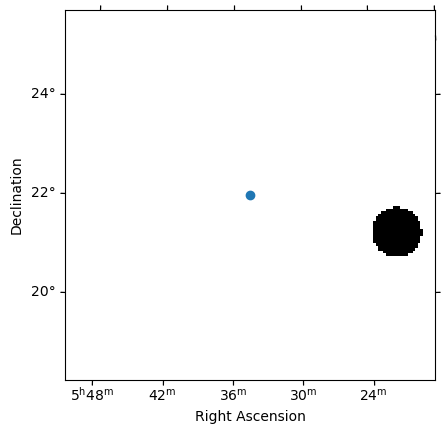

In [12]:
skydir = target_position.galactic
geom = WcsGeom.create(
    npix=(150, 150), binsz=0.05, skydir=skydir, proj="TAN", frame="icrs"
)

exclusion_mask = ~geom.region_mask([exclusion_region])
ax = exclusion_mask.plot()
ax.scatter(target_position.ra, target_position.dec, transform=ax.get_transform("icrs"), label="Crab Nebula")
plt.show()

Create a geometry using `RegionGeom`.

In [14]:
geom = RegionGeom.create(region=on_region,axes=[energy_axis])

Create an empty `SpectrumDataset` based on the defined geometry and true energy axis

In [17]:
dataset_empty = SpectrumDataset.create(geom=geom, energy_axis_true=energy_axis_true)

Create the Maker instance that we are going to need for the data reduction.

`SpectrumDatasetMaker` computes the reduced IRFs (effective area, energy dispersion, and exposure) and fills each SpectrumDataset with the corresponding counts and instrument response information.

`ReflectedRegionsBackgroundMaker` estimates the background using the reflected-region method and extracts the OFF counts for each observation.

`SafeMaskMaker` defines the safe energy range and creates a mask that restricts the analysis to reliable reconstructed energies.

In [19]:
dataset_maker = SpectrumDatasetMaker(
    containment_correction=True, selection=["counts", "exposure", "edisp"]
)
bkg_maker = ReflectedRegionsBackgroundMaker(exclusion_mask=exclusion_mask)
safe_mask_maker = SafeMaskMaker(methods=["aeff-max","edisp-bias"], aeff_percent=10, bias_percent=15)

Run the data reduction loop. 

In [20]:
datasets = Datasets()

for obs, obs_id in zip(observations, observations.ids):
    dataset = dataset_maker.run(dataset_empty.copy(name=obs_id), obs)
    dataset_on_off = bkg_maker.run(dataset, obs)
    dataset_on_off = safe_mask_maker.run(dataset_on_off, obs)
    datasets.append(dataset_on_off)

print(datasets)

Datasets
--------

Dataset 0: 

  Type       : SpectrumDatasetOnOff
  Name       : 23523
  Instrument : HESS
  Models     : 

Dataset 1: 

  Type       : SpectrumDatasetOnOff
  Name       : 23526
  Instrument : HESS
  Models     : 

Dataset 2: 

  Type       : SpectrumDatasetOnOff
  Name       : 23559
  Instrument : HESS
  Models     : 

Dataset 3: 

  Type       : SpectrumDatasetOnOff
  Name       : 23592
  Instrument : HESS
  Models     : 




Info table:

In [21]:
info_table = datasets.info_table(cumulative=True)

In [22]:
info_table

name,counts,excess,sqrt_ts,background,npred,npred_background,npred_signal,exposure_min,exposure_max,livetime,ontime,counts_rate,background_rate,excess_rate,n_bins,n_fit_bins,stat_type,stat_sum,counts_off,acceptance,acceptance_off,alpha
,,,,,,,,m2 s,m2 s,s,s,1 / s,1 / s,1 / s,,,,,,,,
str7,int64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,int64,int64,str5,float64,int64,float64,float64,float64
stacked,112,106.21428680419922,18.84744488450148,5.785714626312256,12.866667203505832,12.866667203505832,nan,261132.46875,812108608.0,1581.736764695497,1687.0000000000016,0.0708082422434945,0.0036578239536754235,0.06715041919421195,27,17,wstat,369.891540214679,81,17.0,237.99998474121094,0.0714285746216774
stacked,217,204.42857360839844,25.671983245235783,12.571429252624512,26.200001093149183,26.200001093149183,nan,1219567.125,1524699136.0,3154.4235137812757,3369.9999999999964,0.06879228456545373,0.003985333357331865,0.06480695211510945,27,18,wstat,666.2287995984093,176,35.0,489.9999694824219,0.0714285746216774
stacked,322,305.05902099609375,33.087435746112924,16.940994262695312,30.25331708446249,30.25331708446249,nan,1750019.0,2011274240.0,4732.546993609518,5056.000000000001,0.06803947228306555,0.003579677980075249,0.06445979752721377,27,18,wstat,1103.3093594100578,377,53.0,1179.4466552734375,0.044936325401067734
stacked,401,379.80902099609375,37.25093782199252,21.190994262695312,35.58576616693781,35.58576616693781,nan,1909606.875,2550689280.0,6313.811659421768,6741.999999999996,0.06351155555956581,0.0033562917942085127,0.06015526618208904,27,18,wstat,1401.786116388056,547,70.0,1806.8995361328125,0.03874039277434349


Plot the reflected regions:

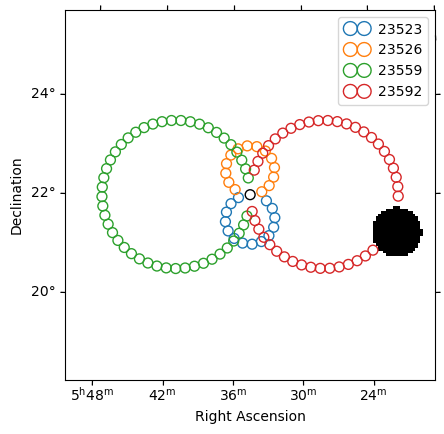

In [23]:
plt.figure()
ax = exclusion_mask.plot()
on_region.to_pixel(ax.wcs).plot(ax=ax, edgecolor="k")
plot_spectrum_datasets_off_regions(ax=ax, datasets=datasets)
plt.show()

Stack the dataset using `stack_reduce`.

In [25]:
stacked = datasets.stack_reduce(name="stacked")
stacked

Create a power-law using the `PowerLawSpectralModel`.

In [41]:
spectral_model = PowerLawSpectralModel(
    index=2,
    amplitude=2e-11*u.Unit("cm-2 s-1 TeV-1"),
    reference=1*u.TeV
)

spectral_model.index.min = 1
spectral_model.index.max = 8
spectral_model.index.frozen = False


Create a `SkyModel`.

In [42]:
sky_model = SkyModel(spectral_model=spectral_model, name="Crab")

Fit the model to the stacked dataset.

In [43]:
stacked.models = sky_model


In [47]:
fit = Fit(backend='minuit',optimize_opts={"migrad_opts": {"ncall": 10000}})
result = fit.run(datasets=stacked)

In [45]:
print(result)

OptimizeResult

	backend    : minuit
	method     : migrad
	success    : True
	message    : Optimization terminated successfully.
	nfev       : 48
	total stat : 13.52

CovarianceResult

	backend    : minuit
	method     : hesse
	success    : True
	message    : Hesse terminated successfully.



In [46]:
print(stacked.models)

DatasetModels

Component 0: SkyModel

  Name                      : Crab
  Datasets names            : None
  Spectral model type       : PowerLawSpectralModel
  Spatial  model type       : 
  Temporal model type       : 
  Parameters:
    index                         :      2.678   +/-    0.08             
    amplitude                     :   4.45e-11   +/- 3.0e-12 1 / (TeV s cm2)
    reference             (frozen):      1.000       TeV         




Plot the residuals:

<Axes: xlabel='Energy [$\\mathrm{TeV}$]', ylabel='Residuals ((data - model) / sqrt(model))'>

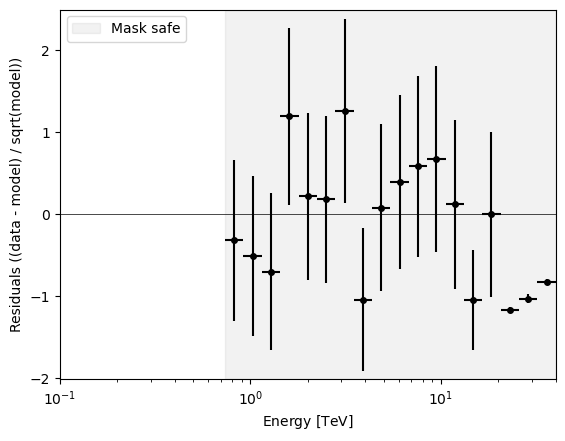

In [48]:
stacked.plot_residuals_spectral(method="diff/sqrt(model)")

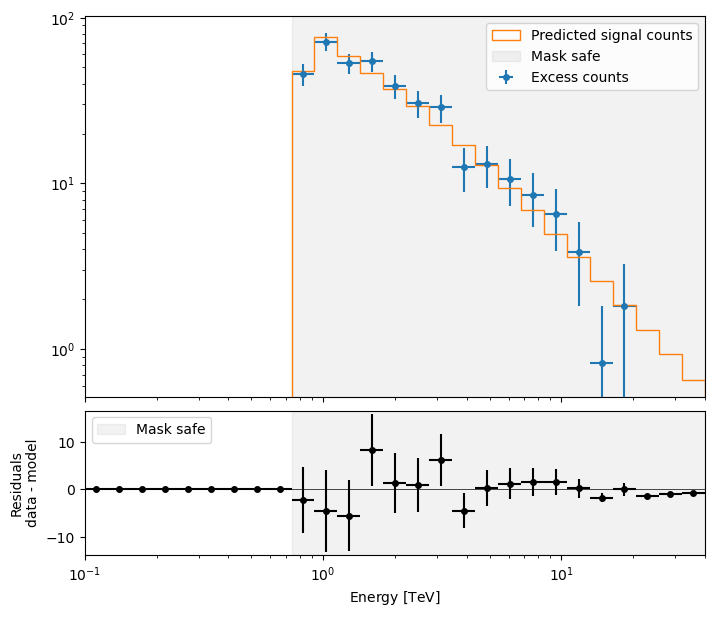

In [49]:
ax_spectrum, ax_residual = stacked.plot_fit()

Text(0, 0.5, 'Delta TS')

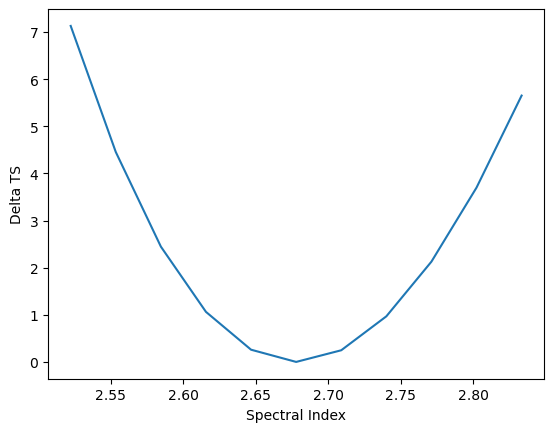

In [50]:
parameter = stacked.models.parameters['index']
profile = fit.stat_profile(stacked, parameter=parameter)
total_stat = result.total_stat

plt.plot(profile['Crab.spectral.index_scan'], profile['stat_scan']-total_stat)
plt.xlabel('Spectral Index')
plt.ylabel('Delta TS')

Extract flux points:

In [51]:
fp = FluxPointsEstimator(
     energy_edges=energy_axis.edges[::2], 
    source="Crab", 
    selection_optional="all"
).run(datasets=stacked)

Plot the model and flux points.

<Axes: xlabel='Energy [$\\mathrm{TeV}$]', ylabel='e2dnde [$\\mathrm{erg\\,s^{-1}\\,cm^{-2}}$]'>

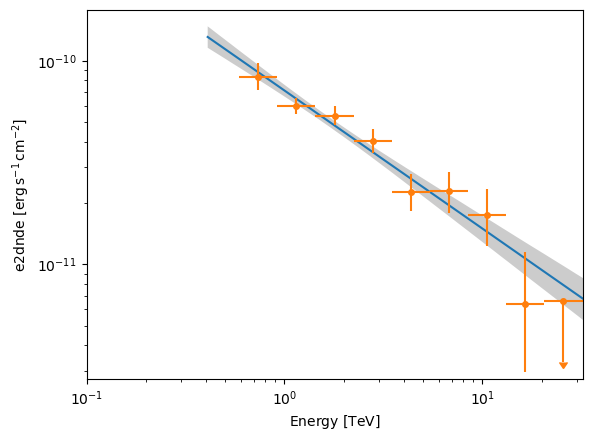

In [56]:
sed_type = "e2dnde"
energy_bounds = [0.4, 40]*u.TeV

stacked.models[0].spectral_model.plot(energy_bounds=energy_bounds, sed_type=sed_type, label="Best fit")
stacked.models[0].spectral_model.plot_error(energy_bounds=energy_bounds, sed_type=sed_type)
fp.plot(sed_type=sed_type, label="Flux Points")--

#### Model significance

Exercise: Is a power-law the best model to describe the data ? 

To answer this question, we propose to use a likelihood ratio test (see Jonathan lecture) test both a `LogParabolaSpectralModel` and an `ExpCutoffPowerLawSpectralModel`.

Are those two models nested models to a power-law respectively ?

Can we apply Wilk's theorem ? 

Knowing that the "total stat" of the fit result is $-2\ln(\mathcal{L})$, where $\mathcal{L}$ is the likelihood, compute the significance of the exponentially cutoff power-law and the log-parabola against t


### 1.2 Point-like IRFs

#### Redo the Crab nebulae analysis using "Point-like" observations from MAGIC

For that you will have to get the data from `$GAMMAPY_DATA/magic/rad_max/data/`. 

To get the observations, `required_irf="point-like"` has to be passed to `DataStore.get_observations`.

Also note that MAGIC energy threshold is lower that H.E.S.S.. You can start your dataset reco energy axis at 50 GeV. Of course, you will have to adapt you true energy in consequences.

Finally, using "point-like" IRFs, it is better to use Wobble regions for the off counts. You can define region_finder of `ReflectedRegionsBackgroundMaker` to `ReflectedRegionsBackgroundMaker`. 